# PLS Regression
We will look at a dataset containing the nutrient contents and calories of various food items from Starbucks.

In [1]:
# Importing modules

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")


                                     item  calories   fat  carb  fiber  \
0                            8-Grain Roll       350   8.0    67      5   
1                       Apple Bran Muffin       350   9.0    64      7   
2                           Apple Fritter       420  20.0    59      0   
3                         Banana Nut Loaf       490  19.0    75      4   
4             Birthday Cake Mini Doughnut       130   6.0    17      0   
..                                    ...       ...   ...   ...    ...   
72        Tarragon Chicken Salad Sandwich       420  13.0    46      6   
73                Turkey & Swiss Sandwich       390  13.0    36      2   
74             Greek Yogurt Honey Parfait       300  12.0    44      0   
75         Peach Raspberry Yogurt Parfait       300   4.0    57      3   
76  Strawberry & Blueberry Yogurt Parfait       300   3.5    60      3   

    protein      type  
0        10    bakery  
1         6    bakery  
2         5    bakery  
3         7    

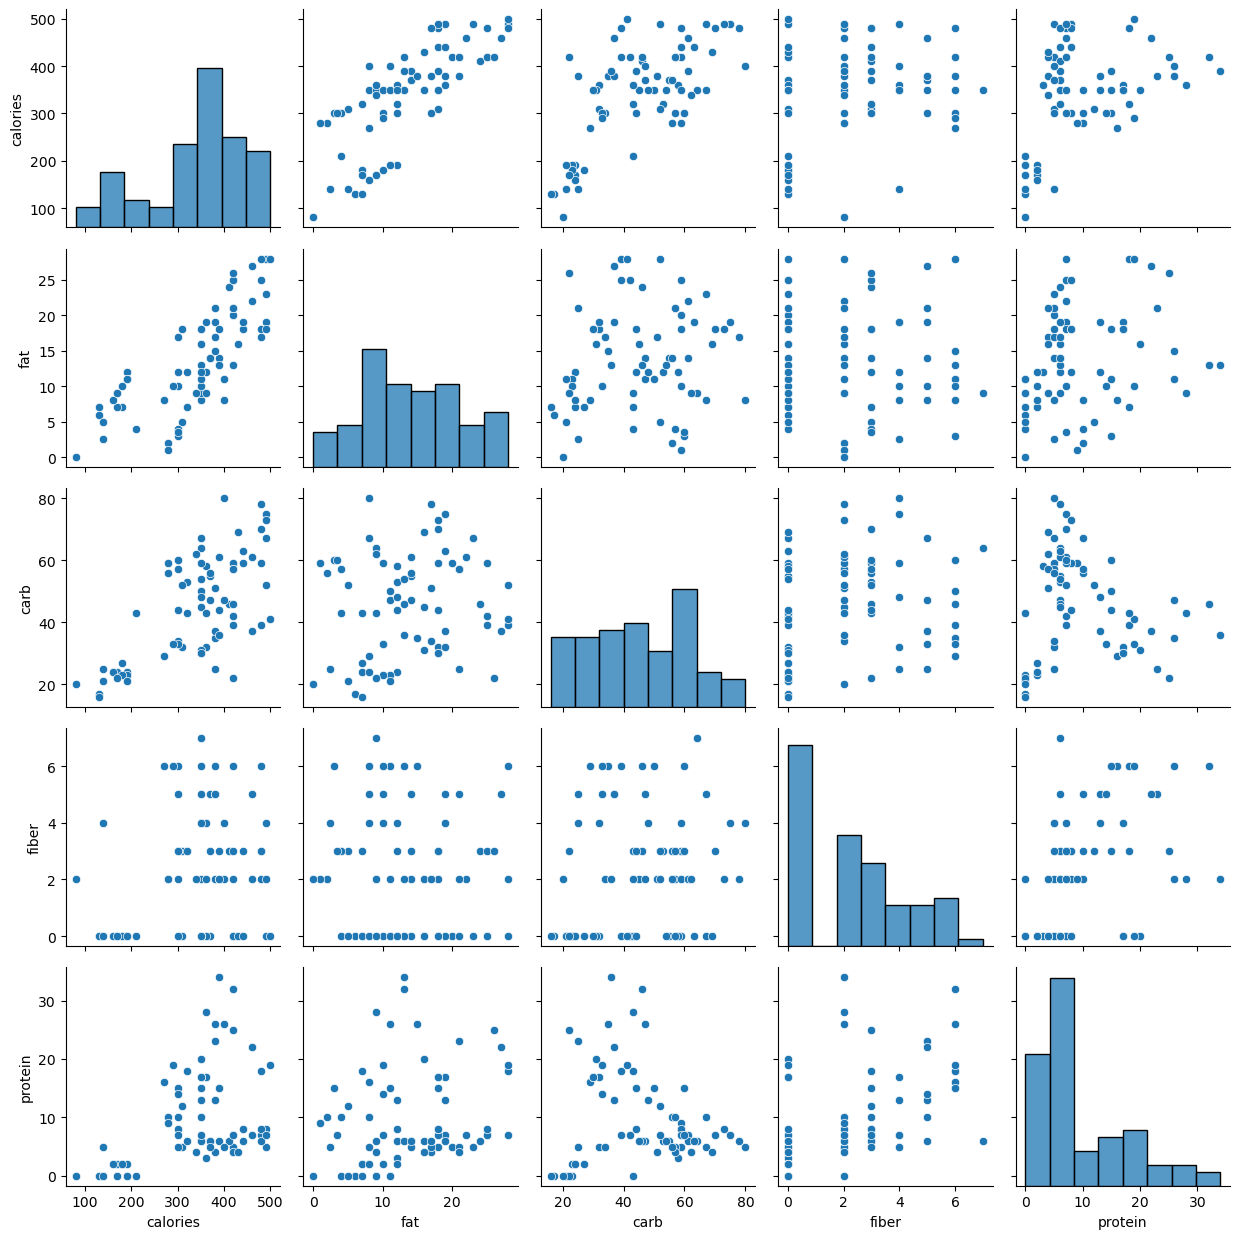

In [2]:
# Loading the data

df = pd.read_csv('starbucks.csv', sep=',', header=0, encoding='latin1')

print(df)

# Visualising the data using pairwise scatter-plots

sns.pairplot(df)
plt.tight_layout()
plt.show()

# Defining the predictor matrix and the response variable 

X=df[['fat', 'carb','fiber','protein','type']]

y=df['calories']


In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Splitting the data into training set and test set
[X_train, X_test, y_train, y_test] = train_test_split(
    X, y, test_size=0.3, random_state=0)

type_train=X_train['type']

X_train=X_train[['fat', 'carb','fiber','protein']]
X_test=X_test[['fat', 'carb','fiber','protein']]

# Standardising the data
ssc = StandardScaler()
ssc.fit(X_train)
X_train_std = ssc.transform(X_train)
X_test_std = ssc.transform(X_test)

# NB! We don't need to standardise y since we only have one column in y.

## Partial Least Squares Regression 


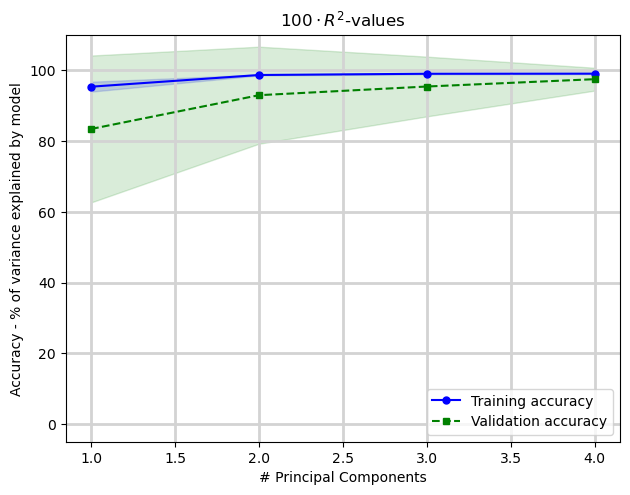

[83.42646537 92.98168651 95.43469743 97.50966537]


In [4]:
from sklearn.cross_decomposition import PLSRegression
from sklearn.model_selection import validation_curve

pls = PLSRegression(scale=False)

# Validation curve (based on Cross Validation) for the parameter estimation
param_range = list(range(1,5))  # We consider PLSR models with 1 to 4 components
[train_scores, test_scores] = validation_curve(
                estimator   = pls, 
                X           = X_train_std, 
                y           = y_train, 
                param_name  = 'n_components', # The paramter to vary
                param_range = param_range,   # ... and its values
                cv          = 10) # Using 10-fold cross-validation

# Calculate validation curves (100*R^2) for training and test sets:
train_mean = np.mean(train_scores, axis=1)*100
train_std  = np.std(train_scores,  axis=1)*100
test_mean  = np.mean(test_scores,  axis=1)*100
test_std   = np.std(test_scores,   axis=1)*100

plt.plot(param_range, train_mean, 
         color='blue', marker = 'o', 
         markersize=5, label  = 'Training accuracy')

plt.fill_between(param_range, train_mean + train_std,
                 train_mean - train_std, alpha=0.15,
                 color='blue')

plt.plot(param_range, test_mean, 
         color = 'green', linestyle='--', 
         marker= 's',    markersize=5, 
         label = 'Validation accuracy')

plt.fill_between(param_range, 
                 test_mean + test_std,
                 test_mean - test_std, 
                 alpha=0.15, color='green')

plt.grid()
plt.legend(loc='lower right')
plt.xlabel('# Principal Components')
plt.ylabel('Accuracy - % of variance explained by model')
plt.ylim([-5, 110.0])
plt.tight_layout()
plt.grid(color='LightGrey', linestyle='-', linewidth=2)
plt.title('$100 \cdot R^2$-values')
plt.show()

print(test_mean)

#### The above validation process shows that PLSR with  2 components is optimal


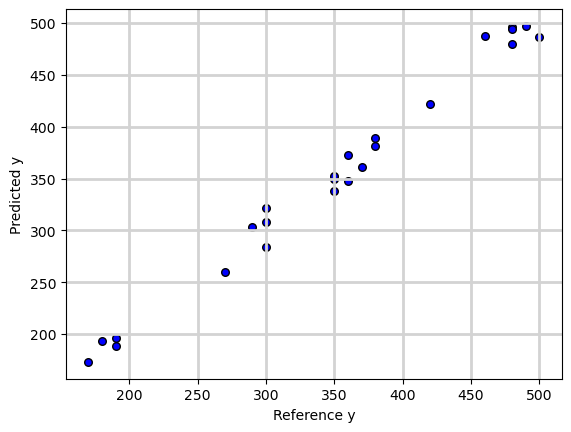

In [5]:
pls = PLSRegression(n_components=2, scale=False) # We use only 2 PCs in the PLSR fitting
pls.fit(X_train_std, y_train)
y_test_pred = pls.predict(X_test_std)

# Plot predicted y versus the reference y
plt.scatter(y_test, y_test_pred, c='blue', edgecolor='black', s=30)
plt.xlabel('Reference y')
plt.ylabel('Predicted y')
plt.grid(color='LightGrey', linestyle='-', linewidth=2)
plt.show()

### Plotting PLSR scores and loadings


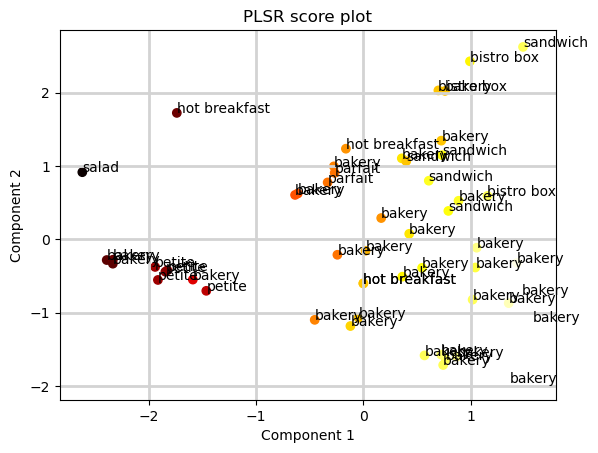

In [6]:
fig, ax = plt.subplots()
ax.scatter(pls.x_scores_[:,0],pls.x_scores_[:,1], c = y_train, cmap='hot')
plt.grid(color='LightGrey', linestyle='-', linewidth=2)
plt.xlabel('Component 1')
plt.ylabel('Component 2')
plt.title('PLSR score plot')
for i, txt in enumerate(type_train):
    ax.annotate(txt, (pls.x_scores_[i,0],pls.x_scores_[i,1]))
plt.show()

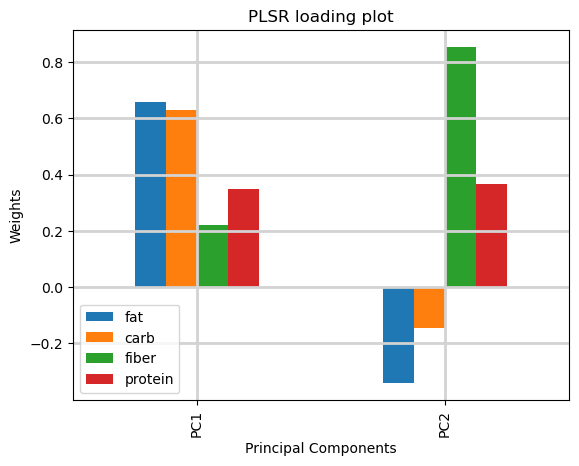

In [7]:
w=pd.DataFrame(pls.x_weights_)

fig, ax = plt.subplots()

w.T.plot(kind='bar',title='PLSR loading plot', ax=ax).legend(loc='lower right')
ax.legend(['fat', 'carb','fiber','protein']);
ax.set_xticklabels(['PC1','PC2'])
plt.grid(color='LightGrey', linestyle='-', linewidth=2)
plt.xlabel('Principal Components')
plt.ylabel('Weights')
plt.show()